# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [2]:
df = pd.read_csv(DATA/ "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

The outcome is salary change. The predictor here is training hours. The expected direction is positive. Possible omitted variables might be a sector of work or years of experience. 

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

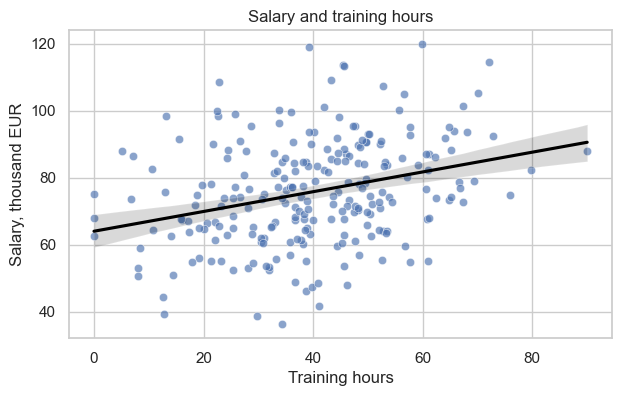

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [4]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        23:39:51   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [5]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
effect_per_hour = slope #corrected the code to display change per additional hour 
#instead of per additional standard deviation unit 
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {effect_per_hour:.3f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.295 thousand EUR


In [6]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "obs_ci_lower", "obs_ci_upper"]])

,training_hours,mean,obs_ci_lower,obs_ci_upper
0,10,66.922063,37.154695,96.689430
1,40,75.775371,46.216819,105.333924
2,80,87.579782,57.636773,117.522792


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

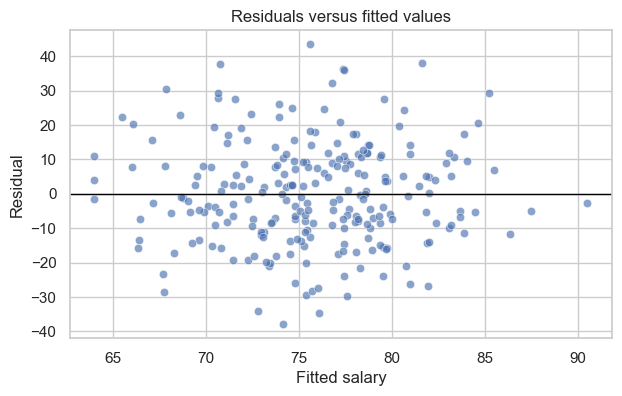

In [7]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

Slope interpretation: Estimated salary change per additional training hour is 0.295 thousand EUR or 295 EUR. This is an expected average, not a necessary proof. R^2 shows that this association explains 9% of salary variation. Years of experience could confound this slope, since it may affect both how much training someone gets and how much they earn.